In [4]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import statsmodels.formula.api as smf

from pathlib import Path

from sklearn.metrics import mean_absolute_error, mean_squared_error

from sklearn.model_selection import train_test_split

project_dr = Path.cwd()

if project_dr.name == "notebooks":
    project_dr = project_dr.parent 


df = pd.read_csv(project_dr/"data"/ "hour.csv")


df.head(1)

df = df.sort_values(["dteday", "hr"]).reset_index(drop = True)

train, test = train_test_split(
    df,
    test_size=0.2,
    shuffle=False)


formula = "cnt ~ temp + hum + windspeed + C(hr) + C(workingday) + C(season)"

linear_model = smf.ols(formula = formula, data = train).fit()

print(linear_model.summary())



                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.633
Model:                            OLS   Adj. R-squared:                  0.632
Method:                 Least Squares   F-statistic:                     796.0
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:17:24   Log-Likelihood:                -83919.
No. Observations:               13903   AIC:                         1.679e+05
Df Residuals:                   13872   BIC:                         1.681e+05
Df Model:                          30                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.4322      6

In [11]:
linear_predictions = linear_model.predict(test)

linear_mae = mean_absolute_error(test["cnt"], linear_predictions)


linear_rmse = np.sqrt(mean_squared_error(test["cnt"], linear_predictions))

print(f"Test MAE: {linear_mae:,.2f}")
print(f"Test RMSE: {linear_rmse:,.2f}")

Test MAE: 109.97
Test RMSE: 158.95


In [8]:
# Simple baseline prediction
baseline_predictions = np.full(
    len(test),
    train["cnt"].mean()
)

baseline_mae = mean_absolute_error(
    test["cnt"],
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test["cnt"],
        baseline_predictions
    )
)

print(f"Baseline MAE: {baseline_mae:.2f}")
print(f"Baseline RMSE: {baseline_rmse:.2f}")

Baseline MAE: 174.98
Baseline RMSE: 232.61


In [10]:
mae_improvement = (baseline_mae - linear_mae) / baseline_mae * 100
rmse_improvement = (baseline_rmse - linear_rmse) / baseline_rmse * 100

print(f"MAE improved by {mae_improvement:.1f}%")
print(f"RMSE improved by {rmse_improvement:.1f}%")

MAE improved by 37.2%
RMSE improved by 31.7%


### Evaluating the Multiple Linear Regression Model

**Model Fit and Statistical Significance**

The multiple linear regression model achieved an R-squared of 0.633 and an adjusted R-squared of 0.632, indicating that approximately 63.3% of the variation in hourly bicycle rental counts was explained by the predictors in the training dataset.

The overall F-test was statistically significant, F(30, 13872) = 796.0, p < .001, suggesting that the predictors were jointly associated with hourly rental demand. 

**Predictive Performance**

The model was evaluated using a chronological training/testing split, with 80% of observations used for training and the remaining 20% reserved for testing.

Comparing the regression model against the baseline model, the regression model produced lower MAE and RMSE values, indicating better predictive performance on unseen data.

Specifically, the regression model reduced MAE by approximately 37% and RMSE by approximately 32% relative to the baseline model. This suggests that incorporating temporal and environmental predictors provides useful predictive information beyond simply predicting the mean rental count.

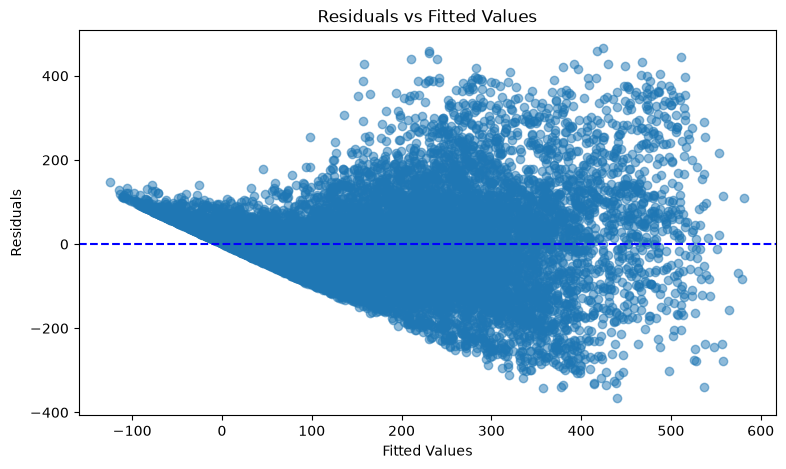

In [12]:
fitted_values = linear_model.fittedvalues
residuals = linear_model.resid

plt.figure(figsize = (9,5))

plt.scatter(fitted_values, residuals, alpha = 0.5)

plt.axhline(0, color = "blue", linestyle = "--")

plt.title("Residuals vs Fitted Values")

plt.xlabel("Fitted Values")

plt.ylabel("Residuals")
plt.show()

In [13]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp = het_breuschpagan(
    linear_model.resid,
    linear_model.model.exog
)

print(f"LM statistic: {bp[0]:.3f}")
print(f"LM p-value: {bp[1]:.5g}")
print(f"F statistic: {bp[2]:.3f}")
print(f"F p-value: {bp[3]:.5g}")

LM statistic: 3673.858
LM p-value: 0
F statistic: 166.074
F p-value: 0


### Assessing Homoscedasticity 

The residuals vs. fitted values plot displays strong funneling pattern to the right, with variance increasing across higher fitted values, thereby provding visual evidence for heteroscedasticity and suggesting the violation of the assumption of constant variance. The Breusch–Pagan test provides further evidence of heteroscedasticity (LM = 3673.86, p < .001). Therefore, we reject the null hypothesis of constant error variance. The model produces some negative fitted values, which are not meaningful for rental counts; this highlights a limitation of using linear regression for modelling the response variable. 




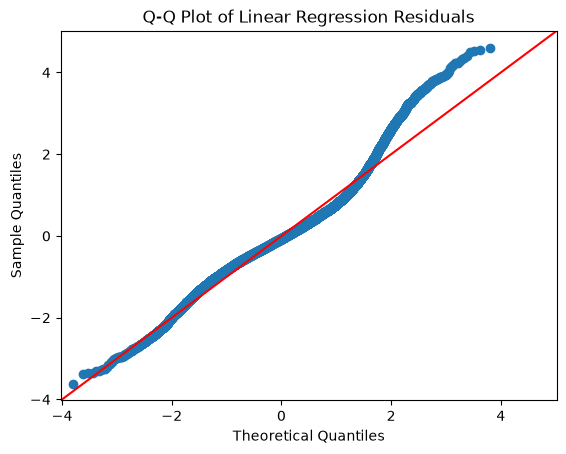

In [16]:
import statsmodels.api as sm

residuals = linear_model.resid

sm.qqplot(
    residuals,
    line="45",
    fit=True
)

plt.title("Q-Q Plot of Linear Regression Residuals")
plt.show()

### Assessing Normality of Residuals

The Q-Q plot reveals departures from the theoretical normal distribution, particularly in the upper tail. Although the residuals approximately follow the reference line through much of the distribution, the upper-tail observations deviate substantially above it.

This suggests that the residual distribution has a heavier upper tail than expected under normality, indicating occasional large positive residuals where the model substantially underpredicts hourly bicycle rental demand.

These observations suggest that the normality assumption may not be appropriate for the fitted OLS model. However, the previously identified heteroscedasticity may also contribute to the observed deviations.

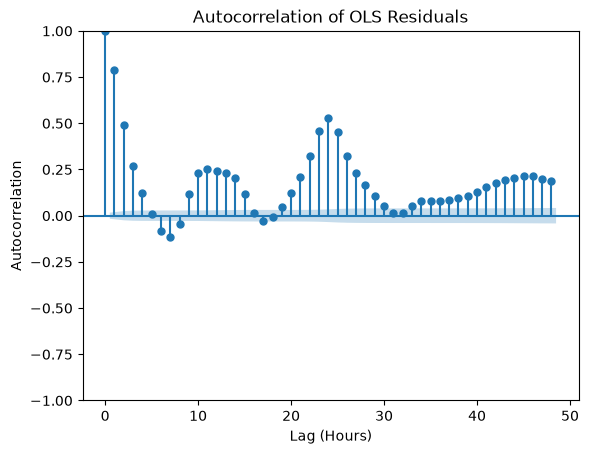

In [17]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(linear_model.resid, lags=48)

plt.title("Autocorrelation of OLS Residuals")
plt.xlabel("Lag (Hours)")
plt.ylabel("Autocorrelation")
plt.show()

### Assessing Independence of Errors

The autocorrelation function (ACF) plot of the OLS residuals reveals substantial positive autocorrelation, particularly at lag 1 (approximately 0.79) and lag 24 (approximately 0.53).

The strong autocorrelation at lag 1 suggests that residuals from consecutive hours are not independent. Additionally, the pronounced peak at lag 24 indicates that daily patterns remain in the residuals despite including hour of day as a categorical predictor.

These findings provide evidence against the independence assumption of the classical linear regression model. Consequently, conventional OLS standard errors, confidence intervals, and hypothesis tests may be unreliable.

However, the presence of autocorrelation does not necessarily invalidate the model's predictive performance, which is evaluated separately using the chronological test dataset.

In [18]:
poisson_model = smf.poisson(
    formula=formula,
    data=train
).fit(maxiter=200)

print(poisson_model.summary())

Optimization terminated successfully.
         Current function value: 23.569398
         Iterations 9
                          Poisson Regression Results                          
Dep. Variable:                    cnt   No. Observations:                13903
Model:                        Poisson   Df Residuals:                    13872
Method:                           MLE   Df Model:                           30
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.7038
Time:                        11:27:54   Log-Likelihood:            -3.2769e+05
converged:                       True   LL-Null:                   -1.1064e+06
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              3.4754      0.007    499.643      0.000       3.462       3.489
C(hr

In [19]:

mu = poisson_model.predict(train)


pearson_chi2 = np.sum(
    (train["cnt"] - mu)**2 / mu
)


df_resid = poisson_model.df_resid


dispersion = pearson_chi2 / df_resid

print(f"Pearson Chi-square: {pearson_chi2:.2f}")
print(f"Residual degrees of freedom: {df_resid:.0f}")
print(f"Dispersion statistic: {dispersion:.2f}")

Pearson Chi-square: 568701.24
Residual degrees of freedom: 13872
Dispersion statistic: 41.00


### Poisson Regression — Initial Results

The Poisson regression model converged successfully using maximum likelihood estimation, with 13,903 training observations.

The model achieved a McFadden pseudo R-squared of 0.7038. The likelihood-ratio test comparing the fitted model with an intercept-only model produced p < .001, although this result should be interpreted cautiously until the model assumptions have been assessed.

The estimated temperature coefficient was positive (β = 1.4677), corresponding to approximately a 15.8% increase in expected hourly bicycle rental counts for a 0.1-unit increase in normalised temperature, holding other predictors constant.

Humidity was negatively associated with expected rental demand (β = −0.5480), corresponding to approximately a 5.3% decrease for a 0.1-unit increase in normalised humidity, holding other predictors constant.

The suitability of the Poisson model will be assessed by examining overdispersion and predictive performance on the held-out testing dataset.

The dispersions statistic was 41, significanlty larger than 1, suggesting overdispersion. 


In [21]:
nb_model = smf.negativebinomial(
    formula=formula,
    data=train
).fit(maxiter=300)

print(nb_model.summary())
alpha = nb_model.params["alpha"]

print(f"Estimated alpha: {alpha:.4f}")

Optimization terminated successfully.
         Current function value: 5.437949
         Iterations: 49
         Function evaluations: 51
         Gradient evaluations: 51
                     NegativeBinomial Regression Results                      
Dep. Variable:                    cnt   No. Observations:                13903
Model:               NegativeBinomial   Df Residuals:                    13872
Method:                           MLE   Df Model:                           30
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.1167
Time:                        11:51:56   Log-Likelihood:                -75604.
converged:                       True   LL-Null:                       -85595.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             

In [22]:
nb_predictions = nb_model.predict(test)

nb_mae = mean_absolute_error(
    test["cnt"],
    nb_predictions
)

nb_rmse = np.sqrt(
    mean_squared_error(
        test["cnt"],
        nb_predictions
    )
)

print(f"Negative Binomial MAE: {nb_mae:.2f}")
print(f"Negative Binomial RMSE: {nb_rmse:.2f}")

Negative Binomial MAE: 107.27
Negative Binomial RMSE: 157.32


### Negative Binomial Regression Results

The negative binomial regression model converged successfully and estimated an overdispersion parameter of α = 0.3304.

This positive estimate supports the presence of variability beyond that permitted by the Poisson mean–variance assumption.

The negative binomial model achieved a training log-likelihood of approximately −75,604, compared with approximately −327,690 for Poisson regression. This indicates a substantially better likelihood fit for the negative binomial model.

On the held-out testing dataset, the negative binomial model achieved an MAE of 107.27 and an RMSE of 157.32 bicycle rentals per hour.

Although the negative binomial model accounts for overdispersion, its predictive performance must be compared with the linear and Poisson regression models before determining which model is most useful for predicting hourly rental counts.

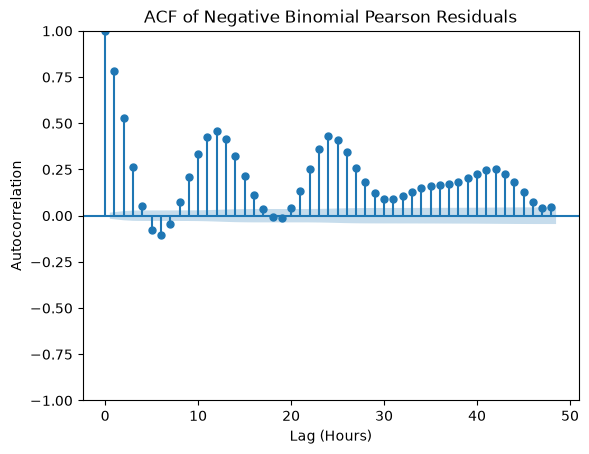

In [25]:
mu_nb = nb_model.predict(train)
alpha = nb_model.params["alpha"]

nb_pearson_residuals = (
    (train["cnt"].to_numpy() - mu_nb.to_numpy())
    / np.sqrt(mu_nb.to_numpy() + alpha * mu_nb.to_numpy()**2)
)


from statsmodels.graphics.tsaplots import plot_acf

plot_acf(nb_pearson_residuals, lags=48)

plt.title("ACF of Negative Binomial Pearson Residuals")
plt.xlabel("Lag (Hours)")
plt.ylabel("Autocorrelation")

plt.show()

### Assessing Residual Autocorrelation — Negative Binomial Regression

The autocorrelation function (ACF) plot of the negative binomial Pearson residuals reveals substantial positive autocorrelation, particularly at lag 1 (approximately 0.78) and lag 24 (approximately 0.43).

These findings suggest that residuals from consecutive hours remain strongly correlated and that daily temporal patterns have not been fully accounted for by the model.

Although negative binomial regression accommodates overdispersion, it does not inherently account for dependence between observations. Consequently, the residual autocorrelation suggests that the model's independence assumption is violated, and conventional standard errors and significance tests may be unreliable.

Future improvements could incorporate additional temporal predictors, interactions between hour of day and working-day status, or time-series modelling techniques to better capture these dependencies.

In [ ]:
poisson_predictions = poisson_model.predict(test)

poisson_mae = mean_absolute_error(
    test["cnt"], poisson_predictions
)

poisson_rmse = np.sqrt(
    mean_squared_error(
        test["cnt"], poisson_predictions
    )
)

comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Poisson Regression",
        "Negative Binomial"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        poisson_mae,
        nb_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        poisson_rmse,
        nb_rms se
    ]
})

comparison = comparison.sort_values("MAE")

print(comparison.round(2))

                Model     MAE    RMSE
2  Poisson Regression  106.20  158.41
3   Negative Binomial  107.27  157.32
1   Linear Regression  109.97  158.95
0            Baseline  174.98  232.61


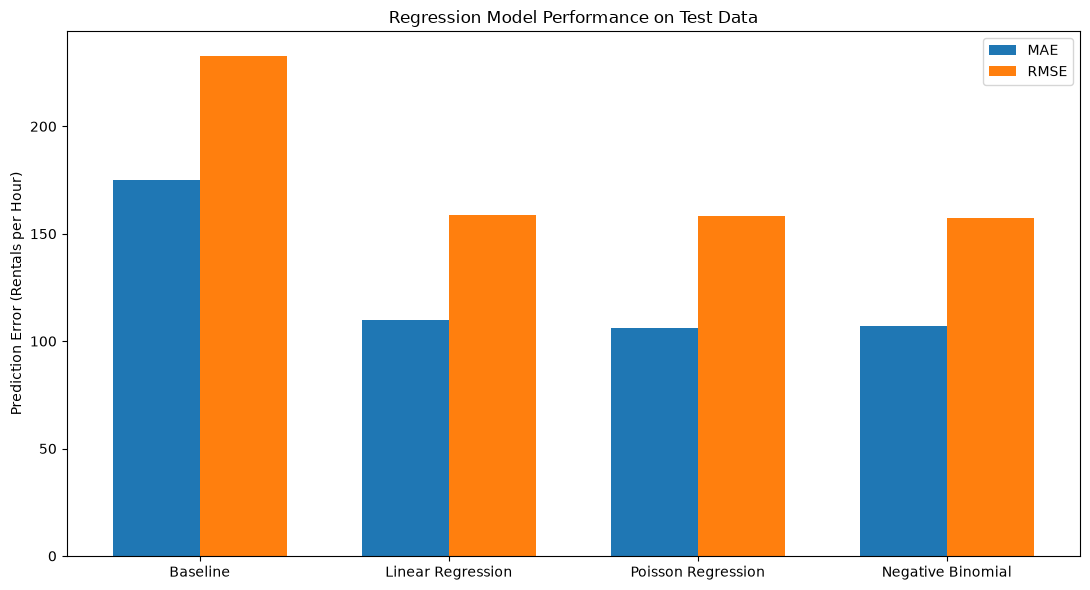

In [28]:
import matplotlib.pyplot as plt
import numpy as np


plot_data = comparison.set_index("Model").loc[
    [
        "Baseline",
        "Linear Regression",
        "Poisson Regression",
        "Negative Binomial"
    ]
]

x = np.arange(len(plot_data))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    plot_data["MAE"],
    width,
    label="MAE"
)

ax.bar(
    x + width / 2,
    plot_data["RMSE"],
    width,
    label="RMSE"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_data.index)

ax.set_ylabel("Prediction Error (Rentals per Hour)")
ax.set_title("Regression Model Performance on Test Data")
ax.legend()

plt.tight_layout()

plt.savefig(
    project_dr / "figures" / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### RQ4: Can Statistical Models Reliably Predict Hourly Bicycle Rental Counts?

#### Model Comparison and Predictive Performance

All three regression models outperformed the baseline model on the held-out chronological testing dataset.

Poisson regression achieved the lowest Mean Absolute Error (MAE = 106.20), representing a 39.3% reduction relative to the baseline (MAE = 174.98). Negative binomial regression achieved the lowest Root Mean Squared Error (RMSE = 157.32), compared with 158.41 for Poisson regression and 158.95 for linear regression.

Despite its strong predictive performance, Poisson regression exhibited substantial overdispersion (Pearson dispersion statistic ≈ 41), indicating that its conditional mean–variance assumption was inadequate.

Negative binomial regression accommodated overdispersion through an estimated dispersion parameter of α = 0.3304 and achieved a substantially better training log-likelihood than Poisson regression. However, residual diagnostics revealed strong temporal autocorrelation, indicating that important time-dependent patterns remained unexplained.

#### Conclusion

The results demonstrate that incorporating temporal and environmental predictors improves hourly bicycle rental predictions compared with simply predicting the historical mean.

However, no single regression model consistently achieved the lowest prediction error across both evaluation metrics. Furthermore, improved predictive accuracy did not necessarily correspond to better satisfaction of distributional assumptions.

Although these models provide useful predictions on the held-out period, remaining temporal dependence and the use of a single historical testing period limit conclusions about their reliability across future periods.

Future improvements could incorporate lagged rental demand, interactions between hour and working-day status, and time-series modelling approaches to better capture temporal dependencies.